![Banner](../images/09_03_banner_rs_rader.png)


# Persistent Scatterer InSAR (PS-InSAR)

This notebook explains Persistent Scatterer InSAR (PS-InSAR), which tracks stable radar reflectors through a long image stack, and applies it with GeoLattice to 24 Sentinel-1 acquisitions of 2025 over Mexico City.


## Overview

Persistent Scatterer InSAR (PS-InSAR) is an advanced radar remote sensing technique designed to measure ground deformation with high precision over time. It works by identifying and analyzing "persistent scatterers", specific points on the ground, such as buildings or rock outcrops, that consistently reflect radar signals across many satellite passes. By tracking these stable points through a long sequence of radar images, PS-InSAR is able to separate true ground movement from other influences like atmospheric effects and measurement noise. This approach enables scientists and engineers to monitor subtle ground motions, such as those caused by subsidence, landslides, or infrastructure settling, with millimeter-level accuracy over large areas and long periods.

Conventional InSAR differences the phase of two SAR acquisitions to measure surface change along the radar line of sight (LOS). It has two main problems:

- **Temporal decorrelation.** Vegetation, soil moisture, and surface change scramble the phase.
- **Atmospheric delay.** It cannot be separated from deformation in a single interferogram.

PS-InSAR (Ferretti et al., 2000, 2001) addresses both by using a long stack of images, usually 20 or more, and keeping only pixels dominated by one strong, stable reflector. Typical examples are building corners, bridges, rock outcrops, poles, and corner reflectors. At such a "persistent scatterer" the phase stays coherent over years, even at large spatial baselines. Because the stack is long, atmospheric and DEM-error terms can be separated from deformation statistically. The result is a millimeter-level LOS displacement time series and a mean velocity at each point.

It helps to compare PS with the other main approach:

| | **PS (point targets)** | **DS / SBAS (distributed scatterers)** |
|---|---|---|
| Scatterer | One dominant, stable reflector per pixel | Many small scatterers, such as fields or bare soil |
| Resolution | Full resolution, no multilooking | Multilooked or spatially filtered |
| Interferogram network | Single reference (star graph) | Small-baseline network |
| Best for | Urban areas, infrastructure, rock | Rural areas, semi-arid land, natural terrain |
| Tools | StaMPS-PS, SARPROZ, MiaplPy (PS part) | MintPy (SBAS), StaMPS-SBAS, Dolphin, MiaplPy |

Modern "PS+DS" methods (SqueeSAR, phase linking in MiaplPy and Dolphin) combine both. NASA's OPERA DISP-S1 product uses Dolphin.


## Core concepts

### Learning objectives

1. Explain how a persistent scatterer keeps a stable phase through a long stack, so deformation can be separated from atmosphere and DEM error.
2. Choose a single reference date that keeps the star network's time spans and perpendicular baselines short.
3. Coregister the Sentinel-1 bursts to that date with back-geocoding and enhanced spectral diversity, at full resolution.
4. Select persistent-scatterer candidates from amplitude dispersion and local peaks of mean amplitude.
5. Estimate phase stability on the wrapped phase, with a DEM-error search and a temporal-coherence threshold.
6. Unwrap the sparse PS network and remove the atmospheric phase screen.
7. Geolocate the Mexico City points, map line-of-sight velocity, and compare it with GNSS and with SBAS.

### Contents

1. Phase model
2. Core algorithm
3. Sentinel-1 workflow
4. PS-InSAR with GeoLattice: Mexico City, 24 Sentinel-1 dates of 2025
5. Summary, exercises and references


## Phase model

For a PS at pixel $\mathbf{r}$ in interferogram $k$, formed with the reference date, the **wrapped** phase after removing flat-earth and topographic phase is:

$$
\phi_k(\mathbf{r}) = W\left\{\phi_{disp,k} + \phi_{\varepsilon,k} + \phi_{atm,k} + \phi_{orb,k} + \phi_{n,k}\right\}
$$

Here $W\{\cdot\}$ is the wrapping operator onto $(-\pi, \pi]$. The terms are:

- **Deformation:** $\phi_{disp,k} = -\dfrac{4\pi}{\lambda}\, d_{LOS}(t_k)$. The sign depends on convention. For Sentinel-1 C-band, $\lambda \approx 5.55$ cm.
- **DEM (look-angle) error:** $\phi_{\varepsilon,k} = \dfrac{4\pi}{\lambda}\dfrac{B_{\perp,k}}{R\sin\theta}\,\Delta h$. This term is proportional to the perpendicular baseline $B_{\perp,k}$, which is why it can be estimated across the stack.
- **Atmospheric phase screen (APS):** $\phi_{atm,k}$. Spatially correlated, temporally uncorrelated.
- **Residual orbit error:** $\phi_{orb,k}$. A smooth ramp. Small for Sentinel-1 with precise orbits.
- **Noise:** $\phi_{n,k}$. Includes decorrelation and thermal noise. It is small at true PS.

With a linear deformation model, $d(t_k) = v\,(t_k - t_{ref})$, the per-point unknowns are the velocity $v$ and the height error $\Delta h$.


## Core algorithm

**1. Coregistration.** Resample all $N$ SLCs to one reference geometry. Sentinel-1 TOPS needs about 0.001-pixel azimuth accuracy, so geometric coregistration is refined with Enhanced Spectral Diversity (ESD). Without ESD, phase jumps appear at burst boundaries.

**2. Single-reference interferograms.** Form $I_k = S_k S_{ref}^*$ for $k \neq ref$, giving $N-1$ interferograms. Then subtract flat-earth and DEM-derived topographic phase.

**3. PS candidate selection.** Compute the amplitude dispersion

$$
D_A(\mathbf{r}) = \frac{\sigma_A(\mathbf{r})}{\mu_A(\mathbf{r})}
$$

on radiometrically calibrated amplitudes. $D_A$ approximates phase standard deviation when the SNR is high. The usual thresholds are:

- **Ferretti:** $D_A < 0.25$ is fairly conservative.
- **StaMPS:** a looser $D_A < 0.4$ is used only for candidates. Final selection is based on phase stability.

**4. Phase-stability estimation (on wrapped phase).** This step works on wrapped phase. Unwrapping comes later.

- **Ferretti approach.** For each point, search $(v, \Delta h)$ to maximize the temporal coherence:

$$
\gamma = \frac{1}{N-1}\left|\sum_{k} e^{\,j\left(\phi_k - \hat\phi_k(v,\Delta h)\right)}\right|
$$

  This is done on arcs between neighboring points, so the atmospheric phase cancels out.

- **Hooper (StaMPS) approach.** Make no assumption about the temporal form of deformation. Instead:
  - Estimate the spatially correlated phase by band-pass filtering neighboring candidates.
  - Subtract it and estimate the spatially uncorrelated DEM error.
  - Compute $\gamma$ from the residual.
  - Iterate, then keep points whose $\gamma$ exceeds the threshold implied by a chosen false-positive rate.

  This makes StaMPS better for non-linear deformation and natural terrain.

**5. Phase unwrapping.** Unwrap the sparse PS network. StaMPS uses 3-D unwrapping (time plus 2-D space) with SNAPHU on a triangulated grid. A reference point or area is chosen, ideally stable ground.

**6. Error separation.**

- **DEM error:** remove the $B_\perp$-correlated phase (StaMPS calls this SCLA).
- **Atmosphere:** filter low-pass in space and high-pass in time, or use external corrections such as GACOS, ERA5, or the TRAIN toolbox.
- **Orbit ramps:** fit and remove planar trends.

**7. Inversion to time series and velocity.** Convert unwrapped, corrected phase to displacement:

$$
d_k = -\frac{\lambda}{4\pi}\,\phi^{unw}_{disp,k}
$$

Velocity is the least-squares slope of $d_k$ against $t_k$. Report it with its standard error, all relative to the reference point.

**8. Geocoding and interpretation.** Use the precise PS height ($h_{DEM} + \Delta h$) for accurate geolocation. To get vertical and east-west motion, combine ascending and descending tracks. Otherwise state clearly that results are in the LOS direction.


## Sentinel-1 workflow


1. **Coregistration:** All Single Look Complex (SLC) images $S_k$ ($k=1\dots N$) are coregistered to a common reference scene $S_{ref}$, so that pixels correspond spatially across the stack: $S_k(x, y)$ refers to the same ground location $(x, y)$ in all scenes.

2. **Forming Interferograms with a Common Reference:** For each subsequent SLC image $S_k$ ($k \neq ref$), form the interferogram with respect to the reference:
   $$
   I_k(\mathbf{r}) = S_k(\mathbf{r}) S_{ref}^*(\mathbf{r})
   $$
   where $\mathbf{r}$ denotes pixel location, and $^*$ denotes the complex conjugate. This yields $N - 1$ interferograms, all referenced to the same epoch.

3. **Selection of Persistent Scatterers:** For each pixel, compute the amplitude dispersion index:
   $$
   D_{amp}(\mathbf{r}) = \frac{\sigma_A(\mathbf{r})}{\mu_A(\mathbf{r})}
   $$
   where $\sigma_A$ is the standard deviation and $\mu_A$ is the mean of the amplitude time series at $\mathbf{r}$. Pixels with $D_{amp}$ below a threshold (commonly $0.25$) are considered Persistent Scatterers (PS). Alternatively, phase stability or spectral tests can be used.

4. **Parameter Estimation for PS Points:** For each PS pixel, the unwrapped interferometric phase $\tilde{\phi}_k(\mathbf{r}_{PS})$ (relative to the reference) is modeled as:
   $$
   \tilde{\phi}_k(\mathbf{r}_{PS}) = \phi_{disp}(t_k) + \phi_{DEM} + \phi_{atm}(t_k) + \phi_{noise}(t_k)
   $$
   - $\phi_{disp}$: phase due to displacement (to be estimated, typically linear in time for velocity, plus possible nonlinear components).
   - $\phi_{DEM}$: phase due to DEM errors (constant per pixel).
   - $\phi_{atm}$: atmospheric phase (varies per image).
   - $\phi_{noise}$: residual noise.
   Parameter estimation is commonly done by time series analysis (e.g., Least Squares, SVD). The linear component yields mean velocity:
   $$
   v_{PS} = \frac{\lambda}{4\pi} \cdot \text{slope}\left[\tilde{\phi}_k\right]
   $$
   where $\lambda$ is radar wavelength.

5. **Result:** Output is a set of point-wise displacement time series $d_k(\mathbf{r}_{PS})$ and mean velocities $v_{PS}$ for each detected persistent scatterer.

**Tools:** ISCE2 `topsStack` + MintPy (SBAS for area-based, PS for point-based), SNAP → StaMPS (PS-InSAR), ASF HyP3 + MintPy (cloud), Dolphin (phase linking), NASA OPERA DISP-S1 (North America ready-made).


### Quality control and validation

- **Map checks.** Inspect PS density and temporal coherence maps.
- **Unwrapping errors.** Look for sudden ±2.8 cm jumps, which equal $\lambda/2$.
- **Validation data.** Compare with GNSS (for example, Nevada Geodetic Lab stations projected to LOS) or leveling.
- **Cross-track check.** Compare ascending against descending results.
- **Reporting.** State the reference point, sign convention (positive meaning toward the satellite is common), LOS geometry, and uncertainty.


### Corrections to the draft

These points would tighten the markdown you provided:

1. **Step 4 phase.** Estimation in PS starts from the **wrapped** phase, using the periodogram/coherence maximization or StaMPS filtering. Unwrapping happens after PS are selected. Also add the orbit term, and write the DEM term explicitly as baseline-dependent: $\phi_{DEM,k} \propto B_{\perp,k}\Delta h$, not a constant.
2. **Velocity formula.** It should carry a sign convention, $v = -\frac{\lambda}{4\pi}\,\text{slope}$, and be computed after atmospheric and DEM corrections.
3. **Step 1 for Sentinel-1.** Add ESD and debursting, and the topographic phase removal step between Steps 2 and 3.
4. **$D_A$ threshold.** $D_A = 0.25$ is Ferretti's threshold. StaMPS uses about 0.4 only for candidates and then selects on phase noise. $D_A$ is only reliable with roughly 30 or more images and calibrated amplitudes.
5. **Tools line.** MintPy itself is SBAS. The PS/DS front end for it is **MiaplPy**. Dolphin does PS+DS phase linking, not PS only.


**Key references:**
- Ferretti, Prati & Rocca (2001), *IEEE TGRS* 39(1).
- Hooper et al. (2004), *GRL* 31.
- Hooper (2008), *GRL* 35 (combined PS/SBAS).
- Ferretti et al. (2011), *IEEE TGRS* 49 (SqueeSAR).


## PS-InSAR with GeoLattice: Mexico City, 24 Sentinel-1 dates of 2025

This section runs the core algorithm above on real data, natively in Python with `geolattice.rsense`.
The site is the same as in Notebook 07_03_01_04 (DInSAR): Mexico City, whose old lake-bed clays
sink by up to tens of centimetres a year as groundwater is pumped from beneath them. A dense city
is where PS-InSAR shines: buildings, walls and street furniture are exactly the stable point
targets it looks for. The PS results are checked against two GNSS stations and against the SBAS
velocities of the DInSAR notebook.

| Core algorithm step | GeoLattice |
|---|---|
| 1 Coregistration (with ESD) | `sar.coregister_stack`, `sar.deburst` |
| 2 Single-reference interferograms, topographic phase removed | `insar.differential_interferogram` |
| 3 PS candidates by amplitude dispersion | `insar.amplitude_dispersion`, `insar.ps_candidates` |
| 4 Phase stability on wrapped phase (StaMPS-style) | `insar.sparse_lowpass`, `insar.ps_periodogram`, `insar.coherence_threshold` |
| 5 Unwrapping the sparse PS network | `insar.unwrap_points` |
| 6 Error separation: DEM error, atmosphere and orbit | `insar.ps_periodogram` (DEM error), `insar.atmospheric_filter` |
| 7 Time series and velocity | `insar.phase_to_los`, `insar.point_velocity`; geolocation with `sar.terrain_correct`, `sar.geocode_points` |

GeoLattice's phase convention is `reference · conj(secondary)` (the complex conjugate of the
$I_k = S_k S_{ref}^*$ written above), so `insar.phase_to_los` gives displacement **toward the
satellite as positive**, and subsidence is negative.

### Data

| Data | Source |
|---|---|
| Sentinel-1 IW SLC bursts, VV, relative orbit 41 (descending), IW1, bursts 086877 to 086878, **24 dates in 2025** | ASF burst extractor (NASA Earthdata login in `~/.netrc`); shares the cache of the DInSAR notebook, `Data/08_remote_sensing/08_03_radar/dinsar_mexico_city/` |
| Precise orbits, Copernicus DEM GLO-30 | AWS `s1-orbits`; Planetary Computer |
| GNSS stations MMX1 and ICMX | Nevada Geodetic Laboratory |
| SBAS velocity map (for comparison) | `outputs/dinsar_mexico_city/` from Notebook 07_03_01_04, if it has been run |

Amplitude dispersion needs a long stack (the theory above suggests 20 to 30 images or more), so this
notebook adds 12 dates to the 12 the DInSAR notebook uses: 24 bursts are downloaded if they are
not cached yet (about 3 GB, 0.9 GB kept).


### Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup for the Mexico City PS example: libraries, the cache shared with the DInSAR notebook,
# the two windows (the cached bursts, and the smaller window that is actually processed),
# the 24 dates of 2025, the GNSS stations and the stable reference area.

import warnings
warnings.filterwarnings("ignore")  # hide library warnings

import time  # timing
import urllib.request  # download GNSS files over HTTP
from pathlib import Path  # file paths

import asf_search as asf  # ASF search and download
import geopandas as gpd  # vector data (the PS points)
import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor on xarray)
import xarray as xr  # labelled rasters
from matplotlib.colors import LightSource  # hillshading
from pyproj import Transformer  # coordinate transformations

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense import insar, sar  # InSAR and SAR processing modules

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
CACHE = Path("../../../../Data/08_remote_sensing/08_03_radar/dinsar_mexico_city")       # bursts, orbits, DEM and GNSS files, reused on later runs
OUT = Path("outputs/psinsar_mexico_city")     # the PS points (GeoPackage) and their displacement time series
for d in (CACHE, OUT):  # create the cache and output folders
    d.mkdir(parents=True, exist_ok=True)  # parents=True also creates missing parent folders

AOI = (-99.24, 19.34, -99.02, 19.50)      # lon/lat of the cached burst windows, the same box as the DInSAR notebook
AOI_PS = (-99.225, 19.36, -99.05, 19.47)  # smaller window actually processed: western hills across to MMX1
UTM = "EPSG:32614"                        # WGS84 / UTM zone 14N, the map grid used when the PS are geocoded
POL = "VV"                                # co-polar channel; it stays coherent longer than VH over the city
BURSTS = ["041_086877_IW1", "041_086878_IW1"]   # relative orbit 41, descending; two bursts so ESD has an overlap
# the 24 acquisition dates of 2025, in time order
DATES = sorted(["2025-01-07", "2025-01-19", "2025-01-31", "2025-02-12", "2025-02-24", "2025-03-08",
                "2025-03-20", "2025-04-13", "2025-04-25", "2025-05-07", "2025-05-25", "2025-06-06",
                "2025-06-18", "2025-07-12", "2025-07-24", "2025-08-05", "2025-08-17", "2025-09-10",
                "2025-09-22", "2025-10-22", "2025-11-03", "2025-11-21", "2025-12-03", "2025-12-15"])
STATIONS = {"MMX1": (-99.0684, 19.4317), "ICMX": (-99.1709, 19.4056)}   # NGL GNSS stations (lon, lat)
STABLE = (-99.2087, 19.3885)                     # reference area in the western hills, the same point as the DInSAR notebook
# version, number of dates and time span
print(f"geolattice.rsense {rs.__version__} | {len(DATES)} dates, {DATES[0]} to {DATES[-1]}")

# ASF searches are cached as small JSON files beside the bursts, so later runs need no network.
import json  # read and write the cached search results
from types import SimpleNamespace  # stand-in for an ASF product read back from the cache


def asf_cached(name, stack=False, **query):
    """ASF search results as objects with .properties and .geometry, cached under CACHE / name.

    The first run searches ASF online and saves the properties and footprint of every result.
    Later runs read that file instead. stack=True keeps the baseline stack of the first result.
    """
    path = CACHE / name  # the cached search
    if path.exists():  # searched before: read the local file
        rows = json.loads(path.read_text())
    else:  # first run: search ASF online and save the result
        res = asf.search(**query)  # the search itself
        rows = [{"properties": p.properties, "geometry": p.geometry}  # results or their stack
                for p in (res[0].stack() if stack else res)]
        path.write_text(json.dumps(rows, default=str))  # keep it for the next run
    return [SimpleNamespace(**r) for r in rows]  # objects with .properties and .geometry, like ASF products


geolattice.rsense 0.3.49 | 24 dates, 2025-01-07 to 2025-12-15


### The stack and the single reference date

A PS stack uses one reference date for all interferograms (a star graph). The reference is
chosen near the centre of the stack in both time and perpendicular baseline, which keeps every
interferogram's temporal and geometric separation as small as possible.


reference date 2025-05-25; B⊥ to the reference -101 to 50 m; {'S1A': 12, 'S1C': 12}


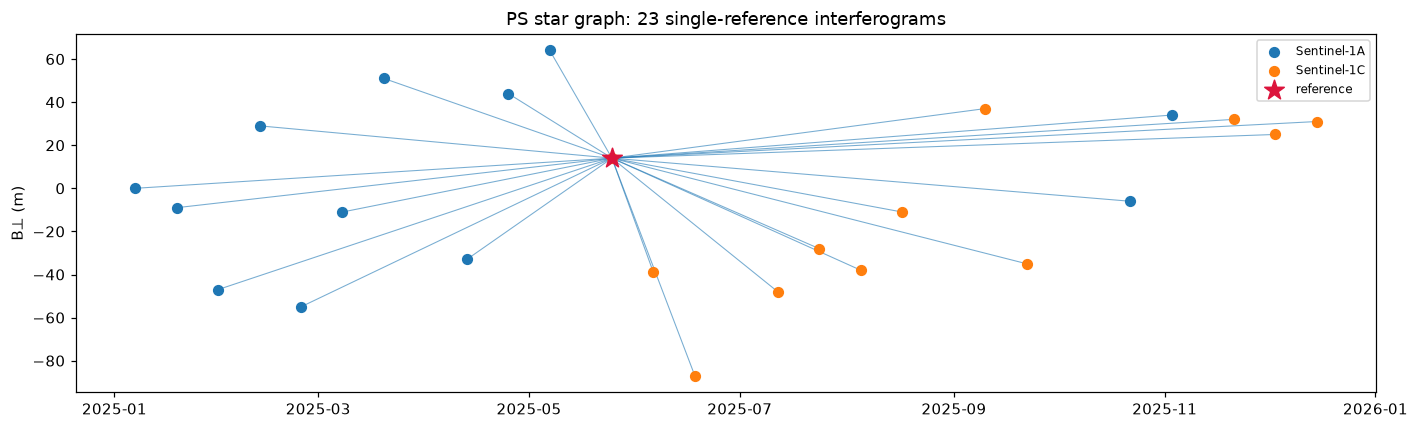

In [2]:
# Choose the single reference date. stack() on one burst lists every acquisition of that
# same burst and the perpendicular baseline of each one relative to the burst we searched for.
# A PS stack is a star: every other date is paired with this one reference.

# 1. The 7 January acquisition of burst 086877 is only the seed of the search. The reference
#    date itself is chosen in step 3, near the centre of the stack.
first_stack = asf_cached("asf_stack_2025.json", stack=True, platform=asf.PLATFORM.SENTINEL1, processingLevel="BURST",
                         fullBurstID=BURSTS[0], polarization=POL, start=DATES[0],
                         end=str(pd.Timestamp(DATES[0]) + pd.Timedelta(days=1)))

# 2. One row per acquisition in the stack: date, satellite (the last character of the platform
#    name is A, B, C or D) and B⊥ in metres. Keep only the 24 dates used below.
stack = pd.DataFrame([{"date": pd.Timestamp(p.properties["startTime"]).tz_convert(None).normalize(),
                       "platform": "S1" + p.properties["platform"][-1], "bperp": p.properties["perpendicularBaseline"]}
                      for p in first_stack]).dropna()
# keep the 24 dates, indexed by date
stack = stack[stack.date.dt.strftime("%Y-%m-%d").isin(DATES)].sort_values("date").set_index("date")

# 3. Score each date by how central it is. The two terms are the total time gap and the total
#    |B⊥| gap to every other date, each divided by the range of that quantity so they weigh
#    the same. The smallest score is the reference: it keeps every interferogram's temporal
#    and geometric separation as small as possible.
days = (stack.index - stack.index[0]).days.values.astype(float)
bp = stack.bperp.values  # perpendicular baselines
# summed normalised time and baseline distance of every date to all others
score = [np.abs(days - days[i]).sum() / np.ptp(days) + np.abs(bp - bp[i]).sum() / np.ptp(bp) for i in range(len(DATES))]
REF = DATES[int(np.argmin(score))]  # the most central date becomes the single reference

# 4. Baselines and time gaps restated relative to that reference, rather than to 7 January.
stack["B⊥ to reference (m)"] = bp - stack.bperp[pd.Timestamp(REF)]
stack["days to reference"] = (stack.index - pd.Timestamp(REF)).days  # time to the reference (days)
# baseline and time spans to the reference
print(f"reference date {REF}; B⊥ to the reference {stack['B⊥ to reference (m)'].min():.0f} to "
      f"{stack['B⊥ to reference (m)'].max():.0f} m; {stack.platform.value_counts().to_dict()}")

# 5. Baseline-time plot of the star graph. Each line joins the reference to one secondary date.
#    Sentinel-1A and 1C are drawn in different colours; the star marks the reference.
fig, ax = plt.subplots(figsize=(13, 4))
for d, r in stack.iterrows():  # each date
    # a line to the reference (star graph)
    ax.plot([pd.Timestamp(REF), d], [stack.bperp[pd.Timestamp(REF)], r.bperp], color="tab:blue", lw=0.7, alpha=0.6)
for p, c in [("S1A", "tab:blue"), ("S1C", "tab:orange")]:  # each platform with its colour
    s = stack[stack.platform == p]  # its acquisitions
    ax.scatter(s.index, s.bperp, s=40, color=c, zorder=3, label=f"Sentinel-1{p[-1]}")  # as points
# the reference date
ax.scatter([pd.Timestamp(REF)], [stack.bperp[pd.Timestamp(REF)]], s=180, marker="*", color="crimson", zorder=4, label="reference")
# labels and title
ax.set(ylabel="B⊥ (m)", title=f"PS star graph: {len(DATES) - 1} single-reference interferograms")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()  # legend, arrange and draw

### Coregistration

Orbits, DEM and burst downloads are as in the DInSAR notebook (Steps 2 to 4 there). The bursts are
cut to the PS window (`sar.burst_window`), and `sar.coregister_stack` co-registers all 23
secondary dates to the reference with back-geocoding and ESD. Besides the resampled SLCs it
returns, for every date and pixel, the range difference at the DEM surface (for topographic phase
removal) and **kz**, the range difference per metre of height: the sensitivity of each
interferogram to a DEM error, which Step 4 estimates.


In [3]:
# Step 1. Precise orbits, the DEM and the burst downloads are the same chain as Steps 2-4 of
# the DInSAR notebook. The bursts are then cut to the smaller PS window and co-registered
# to the reference date chosen above.

# 1. Both bursts on each chosen date. The search window is one day past the last date so that
#    date is included; the list comprehension then drops any extra burst that is not in DATES.
found = asf_cached("asf_bursts_2025.json", platform=asf.PLATFORM.SENTINEL1, processingLevel="BURST",
                   fullBurstID=BURSTS, polarization=POL, start=DATES[0],
                   end=str(pd.Timestamp(DATES[-1]) + pd.Timedelta(days=1)))
res_all = [p for p in found if p.properties["startTime"][:10] in DATES]  # keep the chosen dates
# one row per burst: date, platform, start time and size
acq = pd.DataFrame([{"date": p.properties["startTime"][:10], "platform": p.properties["platform"],
                     "start": pd.Timestamp(p.properties["startTime"]).tz_convert(None),
                     "MB": float(p.properties["bytes"]) / 1e6} for p in res_all])

# 2. One POEORB file per date (it covers both bursts of that pass), from the open AWS bucket.
#    crop_orbit keeps the minutes around the acquisition; the 6 s margin covers the burst length.
eof = {d: sar.download_orbit(g.platform.iloc[0], g.start.min(), CACHE / "orbits") for d, g in acq.groupby("date")}
# precise orbit of each date, cropped to the bursts' time span
orbits = {d: sar.crop_orbit(eof[d], g.start.min(), g.start.max() + pd.Timedelta(seconds=6)) for d, g in acq.groupby("date")}

# 3. Copernicus GLO-30 over a box 0.05° larger than the AOI, so the edges still have elevation.
#    The STAC heights are above the EGM2008 geoid. Orbits and the range-Doppler equations live
#    on the WGS84 ellipsoid, so geoid_to_ellipsoid adds the geoid undulation before they are used.
#    A later run finds the GeoTIFF and skips the download.
dem_file = CACHE / "copdem30_geoid.tif"
if not dem_file.exists():  # download the DEM once
    import planetary_computer as pc  # Planetary Computer URL signing
    import pystac_client  # STAC search client
    from rioxarray.merge import merge_arrays  # mosaic several rasters

    # open the Planetary Computer STAC catalogue
    cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace)
    box = (AOI[0] - 0.05, AOI[1] - 0.05, AOI[2] + 0.05, AOI[3] + 0.05)  # the AOI plus a 0.05 degree margin
    # mosaic the clipped Copernicus DEM tiles and save
    merge_arrays([rioxarray.open_rasterio(i.assets["data"].href).squeeze("band", drop=True).rio.clip_box(*box)
                  for i in cat.search(collections=["cop-dem-glo-30"], bbox=box).items()]).astype("float32").rio.to_raster(dem_file)
dem_geoid = rioxarray.open_rasterio(dem_file).squeeze(drop=True)  # the DEM (heights above the EGM2008 geoid)
ell_file = CACHE / "copdem30_ellipsoid.tif"  # the same DEM above the WGS 84 ellipsoid, saved by an earlier run
if ell_file.exists():  # converted before: read it from the local drive
    dem_ell = rioxarray.open_rasterio(ell_file).squeeze(drop=True)
else:  # first run: add the EGM2008 geoid undulation (PROJ reads the geoid grid online) and save it
    dem_ell = insar.geoid_to_ellipsoid(dem_geoid, "EGM2008")
    dem_ell.rio.to_raster(ell_file)  # keep it for the next run

SLC = CACHE / "slc"  # folder for the cropped bursts
SLC.mkdir(exist_ok=True)  # create it if needed


def fetch_bursts(date):  # download and crop the bursts of one date (skipped when cached)
    # Download one date, crop each burst to the AOI, and cache it. A later run finds the .npy files and returns.
    if all((SLC / f"{date}_{b}.npy").exists() for b in BURSTS):
        return
    # a. The two burst products for this date, downloaded as GeoTIFF + annotation XML.
    res = asf.search(platform=asf.PLATFORM.SENTINEL1, processingLevel="BURST", fullBurstID=BURSTS,
                     polarization=POL, start=date, end=str(pd.Timestamp(date) + pd.Timedelta(days=1)))
    raw = CACHE / "raw"  # folder for the raw downloads
    raw.mkdir(exist_ok=True)  # create it if needed
    rs.access.asf_download(res, raw)  # download the bursts from ASF
    for p in res:  # each burst
        bid, name = p.properties["burst"]["fullBurstID"], p.properties["fileID"]  # burst ID and file name
        # the image and its annotation XML
        tif, xml = next(raw.glob(f"{name}*.tif*")), next(raw.glob(f"{name}*.xml"))
        # b. The annotation holds timing, Doppler polynomials, the orbit and the geolocation grid.
        #    swath is the last three characters of the burst id ("IW1").
        a = sar.read_slc_annotation(xml, swath=bid[-3:], polarisation=POL)
        i = p.properties["burst"]["burstIndex"]  # index of the burst in the annotation
        # c. Column window covering the AOI, plus 300 samples of margin on each side.
        c = sar.burst_window(a, i, AOI, margin=300)
        z = sar.read_slc_burst(tif, a, i, cols=c)  # read only the AOI columns of the burst
        # d. Store the complex burst as two int16 planes (real, imag). The XML and a small JSON
        #    of the crop (burst index, columns kept) stay beside it. The GeoTIFF is then deleted.
        np.save(SLC / f"{date}_{bid}.npy", np.stack([z.real, z.imag]).astype("int16"))
        xml.replace(SLC / f"{date}_{bid}.xml")  # keep the annotation XML in the cache
        # save the burst metadata as JSON
        (SLC / f"{date}_{bid}.json").write_text(pd.Series({"burst_index": i, "col0": c[0], "col1": c[1], "file": name,
                                                           "platform": p.properties["platform"]}).to_json())
        tif.unlink()  # delete the large original TIFF


# 4. Fetch or reload every date. The printed size is the download, not the cropped cache.
#    The cache is shared with the DInSAR notebook, so dates already fetched there are reused.
t0 = time.time()
for date in DATES:  # every date
    fetch_bursts(date)  # download and crop its bursts
# number of bursts, download size and run time
print(f"{len(acq)} bursts ({acq.MB.sum() / 1e3:.1f} GB to download) ready in {time.time() - t0:.0f} s")

# 5. Rebuild each date as the dict coregister_stack expects: one SLC, annotation, burst index
#    and first kept column per burst. apply_orbit_file replaces the metadata orbit with the
#    cropped POEORB state vectors. The cached columns cover the larger AOI; burst_window then
#    cuts them to the PS window, with 250 samples of margin, and the slice is clipped so it
#    never runs past what was cached. The SLC is memory-mapped, so only that slice is read.
members = {}
for date in DATES:  # every date
    m = {"slc": [], "ann": [], "burst": [], "col0": []}  # the bursts of this date as lists
    for b in BURSTS:  # every burst
        meta = pd.read_json(SLC / f"{date}_{b}.json", typ="series")  # burst metadata
        # annotation with the precise orbit applied
        ann = sar.apply_orbit_file(sar.read_slc_annotation(SLC / f"{date}_{b}.xml", swath=b[-3:], polarisation=POL), orbits[date])
        i = int(meta.burst_index)  # burst index
        c0, c1 = sar.burst_window(ann, i, AOI_PS, margin=250)       # cut the cached window to the PS window
        c0, c1 = max(c0, int(meta.col0)), min(c1, int(meta.col1))  # keep only the columns common to all dates
        # read just those columns from the cached array (memory-mapped)
        ri = np.load(SLC / f"{date}_{b}.npy", mmap_mode="r")[:, :, c0 - int(meta.col0):c1 - int(meta.col0)]
        m["slc"].append((ri[0] + 1j * ri[1]).astype("complex64"))  # rebuild the complex SLC
        # annotation, burst index and first column
        m["ann"].append(ann); m["burst"].append(i); m["col0"].append(c0)
    members[date] = m  # the bursts of this date

# 6. Wavelength of the reference burst, used from here on to turn phase into metres and height.
a0 = members[REF]["ann"][0]
lam = a0["wavelength"]  # radar wavelength (m)

# 7. Back-geocoding plus ESD, for every secondary date at once. coregister_stack resamples each
#    date onto the reference grid and returns, per date and pixel, the resampled SLC, the range
#    difference at the DEM surface, and kz (metres of range difference per metre of height).
#    esd=True estimates the along-track shift from the burst overlap and applies it.
t0 = time.time()
# co-register every date to the reference (back-geocoding plus ESD)
co = sar.coregister_stack(members[REF], {d: members[d] for d in DATES if d != REF}, dem_ell, esd=True)
# stack size and run time
print(f"{len(DATES) - 1} secondary dates x {len(BURSTS)} bursts ({members[REF]['slc'][0].shape[1]} range samples) "
      f"co-registered in {time.time() - t0:.0f} s; ESD corrections {min(v['esd']['shift_lines'] for v in co['stack'].values()):+.4f} "
      f"to {max(v['esd']['shift_lines'] for v in co['stack'].values()):+.4f} pixels")

48 bursts (5.9 GB to download) ready in 0 s


23 secondary dates x 2 bursts (5153 range samples) co-registered in 890 s; ESD corrections -0.0152 to +0.0167 pixels


In [4]:
# Deburst. The two bursts are still separate after co-registration; deburst joins them on the
# reference geometry and drops the redundant overlap lines. PS-InSAR keeps this full resolution:
# a point target is smaller than a pixel, so the stack is not multilooked.

anns_ref, ids_ref = members[REF]["ann"], members[REF]["burst"]


def deburst(layers):  # join the bursts of one layer into one image
    # Stitch the burst layers into one image. Every date uses the reference burst timing,
    # because that is the grid they were resampled onto.
    return sar.deburst(list(layers), anns_ref[0], ids_ref, anns=anns_ref)


# 1. The reference SLC, and each secondary's resampled SLC, range difference and kz,
#    all on the debursted grid. times is the zero-Doppler time of each debursted line.
SECS = [d for d in DATES if d != REF]
ref_slc, times = deburst(members[REF]["slc"])  # reference SLC and its azimuth times
sec_slc = {d: deburst(co["stack"][d]["slc"])[0] for d in SECS}  # co-registered secondary SLCs
drange = {d: deburst(co["stack"][d]["delta_range"])[0] for d in SECS}  # range offsets of the secondaries
kz = {d: deburst(co["stack"][d]["kz"])[0] for d in SECS}  # height-to-phase factor (kz) of each secondary

# 2. DEM height, incidence and slant range on the same grid. az_m is the azimuth spacing;
#    rg_m is the ground-range spacing (slant spacing divided by sin of the incidence angle),
#    so the filters and plots below are in metres on the ground rather than in slant range.
geom = {k: deburst(co["geometry"][k])[0] for k in ("dem_height", "incidence", "slant_range")}
H, W = ref_slc.shape  # image size
col0 = members[REF]["col0"][0]  # first range column
az_m = a0["azimuth_pixel_spacing"]  # azimuth pixel size (m)
# ground range pixel size (m)
rg_m = a0["range_pixel_spacing"] / np.sin(np.radians(np.nanmedian(geom["incidence"])))
print(f"debursted full-resolution stack: {len(DATES)} dates x {H} lines x {W} samples "  # stack size
      f"({H * az_m / 1e3:.1f} km x {W * rg_m / 1e3:.1f} km; pixel {az_m:.1f} m x {rg_m:.1f} m on the ground)")

debursted full-resolution stack: 24 dates x 2795 lines x 5153 samples (39.2 km x 22.8 km; pixel 14.0 m x 4.4 m on the ground)


The reference date that best centres the stack is **25 May 2025** (a Sentinel-1C acquisition). Perpendicular baselines to it span −101 to +50 m, and the 24 dates are split evenly between Sentinel-1A and 1C.

Co-registering 23 dates × 2 bursts over 5,153 range samples takes about 15 minutes. ESD corrections range from −0.015 to +0.017 pixels, up to about 24 cm along track: the size of the Sentinel-1A/1C timing offset the DInSAR notebook found, and invisible to geometric co-registration alone.

The debursted stack is 24 dates × 2,795 lines × 5,153 samples, with pixels of 14.0 m (azimuth) × 4.4 m (ground range). PS-InSAR works at this full resolution.

### Single-reference interferograms and PS candidates

The 23 interferograms are formed at full resolution, without multilooking (a point target is
smaller than a pixel), with flat-Earth and topographic phase removed
(`insar.differential_interferogram`). PS candidates are pixels with a low **amplitude
dispersion** D_A over the 24 calibrated amplitudes (`insar.amplitude_dispersion` normalises each
date by its median amplitude first). We use Ferretti's D_A < 0.25 and keep one candidate per
local amplitude peak (3 × 3 window): a bright point target spreads into its neighbours through the
sinc-shaped impulse response, and those side lobes are not independent scatterers.


PS window: lines 701-1807 (354 km²); median D_A 0.46 (fully developed speckle: 0.52); D_A < 0.25: 6.6% of pixels; candidates after the peak test: 95,710 (270 per km²); D_A < 0.4 would give 244,417
86,634 candidates with complete geometry for all 23 interferograms


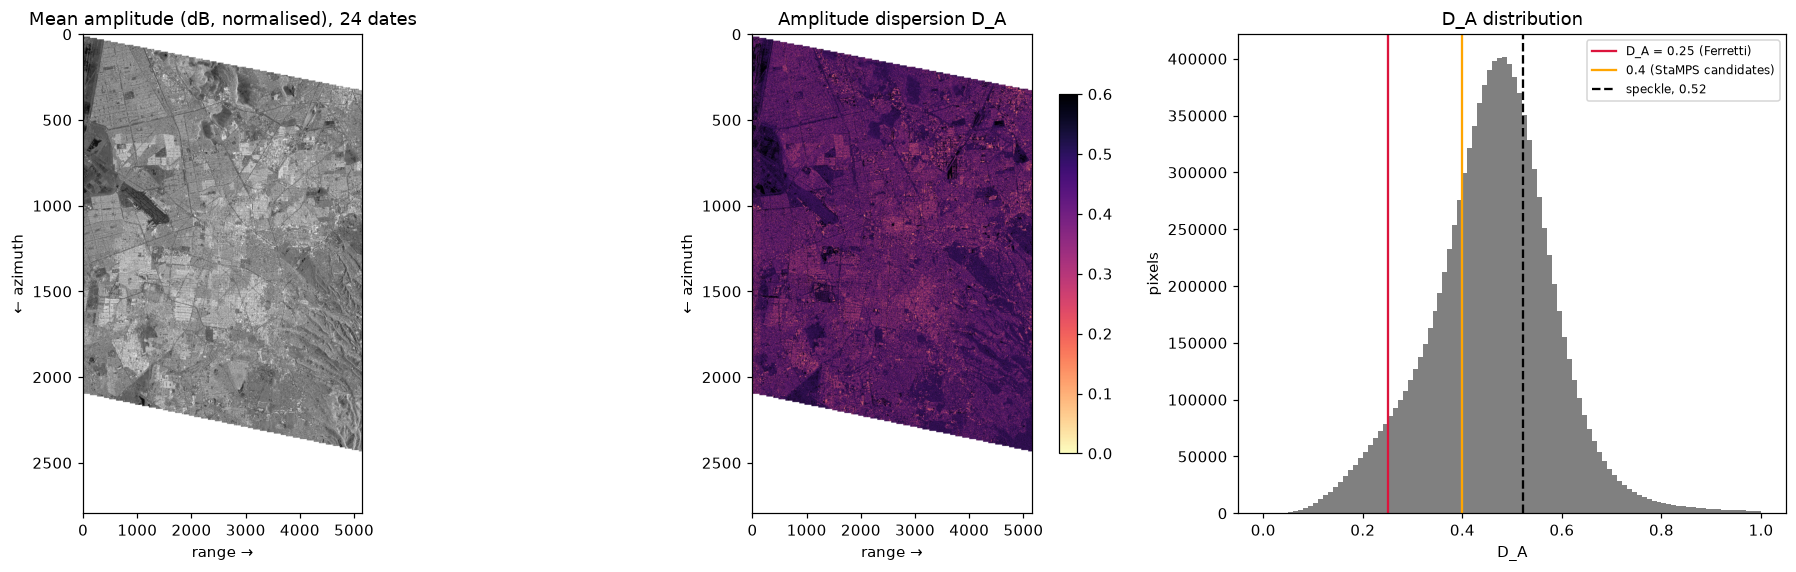

In [5]:
# Steps 2 and 3. Form the 23 single-reference interferograms at the candidate pixels only,
# and choose those candidates from the amplitude dispersion of the 24 dates.

# 1. Amplitude of every date, stacked as (date, line, sample). amplitude_dispersion divides
#    each date by its median amplitude first, so a brighter acquisition does not raise D_A,
#    then returns D_A = σ_A / μ_A and the mean amplitude.
amp = np.stack([np.abs(ref_slc)] + [np.abs(sec_slc[d]) for d in SECS]).astype("float32")
# amplitude dispersion D_A = std / mean of the amplitude, and the mean amplitude
DA, mean_amp = insar.amplitude_dispersion(amp)

# 2. The two bursts cover more ground along track than the PS window. geo2rdr converts the
#    four corners of AOI_PS to radar time (2,240 m is a rough elevation of the city), and
#    interpolating those times onto the line times gives the line range to keep.
corner_lon, corner_lat = np.meshgrid([AOI_PS[0], AOI_PS[2]], [AOI_PS[1], AOI_PS[3]])
# radar times of the four corners of the PS window
t_c, _ = sar.geo2rdr(corner_lat.ravel(), corner_lon.ravel(), np.full(4, 2240.0), anns_ref[0]["orbit"])
# azimuth times -> image rows
rows_c = np.interp((t_c - times[0]) / np.timedelta64(1, "s"), (times - times[0]) / np.timedelta64(1, "s"), np.arange(H))
r_lo, r_hi = int(rows_c.min()), int(np.ceil(rows_c.max()))  # first and last row of the window
inside = np.zeros((H, W), bool)  # mask of the window
inside[r_lo:r_hi + 1] = True  # rows inside the window
area_km2 = (r_hi - r_lo + 1) * az_m * W * rg_m / 1e6  # area of the window (km²)

# 3. A candidate has D_A < 0.25 (Ferretti), is a local peak of the mean amplitude in a 3 x 3
#    window (the side lobes of a bright point are not separate scatterers), lies inside the
#    PS window, and has amplitude on every date.
cand = insar.ps_candidates(DA, 0.25, mean_amplitude=mean_amp, peak_window=3) & inside & np.all(amp > 0, axis=0)
rr, cc = np.nonzero(cand)  # rows and columns of the candidates
d_in = DA[inside]  # D_A inside the window
# window size and D_A statistics
print(f"PS window: lines {r_lo}-{r_hi} ({area_km2:.0f} km²); median D_A {np.nanmedian(d_in):.2f} (fully developed speckle: 0.52); "
      f"D_A < 0.25: {np.mean(d_in < 0.25):.1%} of pixels; candidates after the peak test: {cand.sum():,} "
      f"({cand.sum() / area_km2:.0f} per km²); D_A < 0.4 would give "
      f"{(insar.ps_candidates(DA, 0.4, mean_amplitude=mean_amp, peak_window=3) & inside).sum():,}")

# 4. Phase sensitivity to height, 4π/λ · kz, at each candidate and each secondary date.
#    A candidate that falls outside the DEM footprint of any date has a non-finite kz and is dropped.
kz_ph = np.stack([4 * np.pi / lam * kz[d][rr, cc] for d in SECS])
geo_ok = np.all(np.isfinite(kz_ph), axis=0)            # outside the DEM-geometry footprint of some date
rr, cc, kz_ph = rr[geo_ok], cc[geo_ok], kz_ph[:, geo_ok]  # keep candidates with complete geometry

# 5. The differential interferogram at the surviving candidates: reference times the conjugate
#    of the secondary, with the flat-Earth and topographic phase removed using the range
#    difference at the DEM surface. Only the candidate pixels are computed.
ifg_c = np.stack([insar.differential_interferogram(ref_slc[rr, cc], sec_slc[d][rr, cc], drange[d][rr, cc], lam) for d in SECS])
phase = np.angle(ifg_c)  # wrapped interferometric phase of every candidate
# number of candidates
print(f"{len(rr):,} candidates with complete geometry for all {len(SECS)} interferograms")

# 6. Position of each candidate in metres of ground range and azimuth. The spatial filters
#    below use these rather than pixel indices, because a pixel is about 14 m by 4 m.
px, py = cc * rg_m, rr * az_m                     # metric radar-geometry coordinates for spatial filtering

# 7. Mean amplitude, the D_A map, and the histogram. The dashed line at 0.52 is the D_A of
#    fully developed speckle, sqrt(4/π − 1). aspect stretches range so the pixels look square.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.3))
asp = az_m / rg_m  # pixel aspect ratio in ground units
axes[0].imshow(10 * np.log10(mean_amp), cmap="gray", vmin=-8, vmax=8, aspect=asp)  # mean amplitude
axes[0].set_title("Mean amplitude (dB, normalised), 24 dates")  # title
im = axes[1].imshow(DA, cmap="magma_r", vmin=0, vmax=0.6, aspect=asp)  # amplitude dispersion
axes[1].set_title("Amplitude dispersion D_A"); plt.colorbar(im, ax=axes[1], shrink=0.75)  # title and colour bar
axes[2].hist(DA[np.isfinite(DA)].ravel(), bins=np.linspace(0, 1, 101), color="0.5")  # histogram of D_A
# common selection thresholds
axes[2].axvline(0.25, color="crimson", label="D_A = 0.25 (Ferretti)"); axes[2].axvline(0.4, color="orange", label="0.4 (StaMPS candidates)")
axes[2].axvline(np.sqrt(4 / np.pi - 1), color="k", ls="--", label="speckle, 0.52")  # D_A of pure speckle
# labels, title and legend
axes[2].set(xlabel="D_A", ylabel="pixels", title="D_A distribution"); axes[2].legend(fontsize=8)
for ax in axes[:2]:  # the two image panels
    ax.set(xlabel="range →", ylabel="← azimuth")  # axis labels
plt.tight_layout(); plt.show()  # arrange and draw

Inside the PS window (354 km², lines 701 to 1807), the median D_A is 0.46, a little below the 0.52 of fully developed speckle, because a city has many partly stable pixels. 6.6 % of pixels have D_A < 0.25. Keeping one candidate per amplitude peak leaves **95,710 candidates (270 per km²)**; StaMPS's looser 0.4 would admit 244,417. Of these, 86,634 have valid geometry (the height sensitivity kz) in all 23 interferograms; the rest sit at the edge of the DEM footprint of some date.

In the D_A map, the low-dispersion pixels (the light speckles) are scattered through the built-up city; open ground and vegetation sit near the speckle value.

### Phase stability: spatially correlated phase, DEM error and temporal coherence

D_A only predicts phase stability; Step 4 measures it, on the wrapped phase, following StaMPS:

1. The **spatially correlated phase** of each interferogram (deformation, atmosphere, orbit) is
   estimated at every candidate from its neighbours (`insar.sparse_lowpass`, a Gaussian of 300 m on
   the candidates' phasors, each point's own phase left out) and removed.
2. What remains is the point's own **DEM error** (proportional to kz, so to B⊥) plus noise.
   `insar.ps_periodogram` finds the height error that maximises the **temporal coherence** γ.
3. The DEM-error phase is subtracted before the next estimate of the spatially correlated phase,
   and the two steps are iterated three times.

A point is a PS when γ exceeds what random phase would reach with the same estimator:
`insar.coherence_threshold` simulates random-phase pixels and returns the 99th percentile
(a 1 % false-positive rate).


iteration 1: median temporal coherence 0.952


iteration 2: median temporal coherence 0.952


iteration 3: median temporal coherence 0.952


phase-stability estimation for 86,634 candidates: 19 s
random-phase threshold (1 % false positives, 23 interferograms): γ > 0.490; PS: 83,789 of 86,634 candidates (97%), 237 per km²


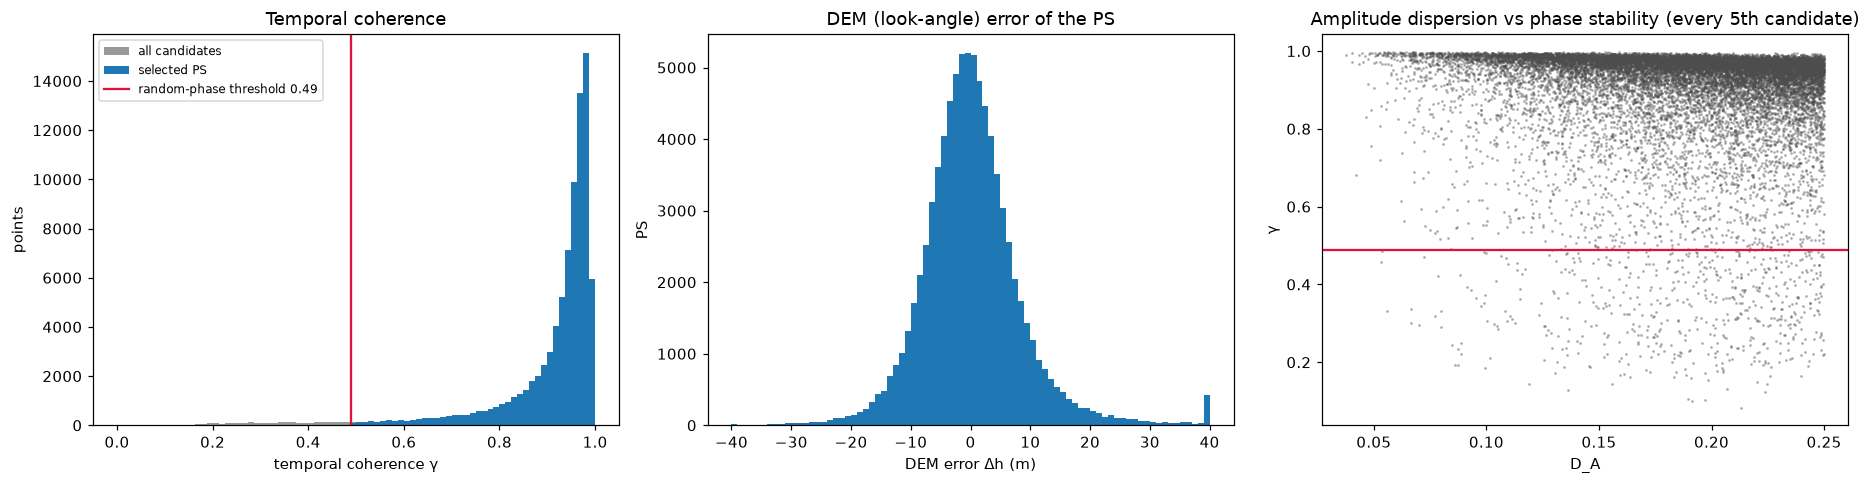

In [6]:
# Step 4. Estimate phase stability on the wrapped phase, following StaMPS. Three iterations
# alternate a spatial low-pass (the phase shared by neighbours) with a search for each
# point's own DEM error.

# 1. Start with no DEM error. Each iteration:
#    a. sparse_lowpass averages neighbouring candidates' phasors with a 300 m Gaussian.
#       cell=50 bins them onto a coarse grid first; exclude_self keeps a point from confirming itself.
#    b. Subtract that spatially correlated phase. What remains is the point's own phase.
#    c. ps_periodogram tries height errors from -40 m to +40 m in 0.5 m steps and keeps the
#       one that maximises the temporal coherence γ.
dh = np.zeros(phase.shape[1])
t0 = time.time()  # start the timer
for it in range(3):  # three iterations
    # low-pass (spatially correlated) phase of the neighbours, after removing the DEM-error term
    low = insar.sparse_lowpass(np.exp(1j * (phase - kz_ph * dh)), px, py, cell=50, sigma=300, exclude_self=True)
    resid = np.angle(np.exp(1j * phase) * np.conj(low / np.abs(low)))  # residual phase of each point
    # periodogram: DEM error and temporal coherence that best explain the residual
    fit = insar.ps_periodogram(resid, kz_ph, dem_error=np.arange(-40, 40.25, 0.5))
    dh, gamma = fit["dem_error"], fit["coherence"]  # update the DEM error and coherence
    print(f"iteration {it + 1}: median temporal coherence {np.median(gamma):.3f}")  # progress

# 2. The threshold is the 99th percentile of γ that this same estimator reaches on pure noise,
#    given this stack's kz values (a 1 % false-positive rate). A candidate above it is a PS.
thr = insar.coherence_threshold(np.nanmedian(kz_ph, axis=1), fpr=0.01)
ps = gamma > thr  # persistent scatterers: coherence above the random-phase threshold
print(f"phase-stability estimation for {phase.shape[1]:,} candidates: {time.time() - t0:.0f} s")  # run time
# threshold and number of selected points
print(f"random-phase threshold (1 % false positives, {len(SECS)} interferograms): γ > {thr:.3f}; "
      f"PS: {ps.sum():,} of {ps.size:,} candidates ({ps.mean():.0%}), {ps.sum() / area_km2:.0f} per km²")

# 3. The γ histogram (all candidates, and those kept), the DEM errors of the PS, and D_A
#    against γ. The horizontal line is the threshold; points below it failed on phase, not on amplitude.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
# coherence of all candidates
axes[0].hist(gamma, bins=np.linspace(0, 1, 81), color="0.6", label="all candidates")
# coherence of the selected PS
axes[0].hist(gamma[ps], bins=np.linspace(0, 1, 81), color="tab:blue", label="selected PS")
axes[0].axvline(thr, color="crimson", label=f"random-phase threshold {thr:.2f}")  # the threshold
# labels, title and legend
axes[0].set(xlabel="temporal coherence γ", ylabel="points", title="Temporal coherence"); axes[0].legend(fontsize=8)
axes[1].hist(dh[ps], bins=np.arange(-40, 41, 1), color="tab:blue")  # DEM errors of the PS
# labels and title
axes[1].set(xlabel="DEM error Δh (m)", ylabel="PS", title="DEM (look-angle) error of the PS")
axes[2].scatter(DA[rr, cc][::5], gamma[::5], s=1, alpha=0.3, color="0.3")  # D_A against coherence
axes[2].axhline(thr, color="crimson")  # the threshold
# labels and title
axes[2].set(xlabel="D_A", ylabel="γ", title="Amplitude dispersion vs phase stability (every 5th candidate)")
plt.tight_layout(); plt.show()  # arrange and draw

The temporal coherence of the candidates is high (median 0.95). The random-phase threshold for 23 interferograms and this estimator is **γ > 0.49** at a 1 % false-positive rate, and 83,789 of the 86,634 candidates (97 %) pass: **237 PS per km²**. Few candidates fail because D_A < 0.25 is already a strict pre-selection in a city; in the D_A-γ scatter, the points that fail are spread across all D_A values.

The DEM errors are centred on zero with a spread of about ±7 m, and a tail of positive values. Copernicus DEM is a surface model, so building tops are already in it; what remains is mostly where the scatterer sits on a building (a roof edge versus the ground-level corner), plus buildings newer than the DEM. A small pile-up at the +40 m search limit marks points whose height error lies beyond the search range.

### Unwrapping the sparse PS network

With the DEM error removed, each PS's phase is wrapped deformation, atmosphere and noise relative
to the reference date. `insar.unwrap_points` unwraps sparse points through a coarse grid: the PS
phasors are averaged in 100 m cells, SNAPHU unwraps that grid, and each point gets its cell's
unwrapped phase plus its own (small, wrapped) difference from the cell.

Unwrapping each single-reference interferogram on its own has a weakness: a point that moves
differently from its neighbours by more than half a cycle *over the whole interval to the
reference date* takes its neighbours' cycle count. With `sequential=True` the phases are put in
time order, the differences between **consecutive dates** (12 to 36 days apart) are unwrapped
instead, and summed. That exploits the continuity in time that StaMPS's 3-D unwrapping uses. Both
are run here for comparison. The result is referred to the PS in the stable western hills, within
700 m of the reference point used in the DInSAR notebook.


In [7]:
# Step 5. Unwrap the PS network. With the DEM-error phase removed, what remains at each PS
# is wrapped deformation, atmosphere and noise, relative to the reference date.

# 1. Radar position of the selected PS, and their phase after subtracting kz · Δh.
#    Taking the angle of the complex exponential wraps that subtraction back onto (-π, π].
prr, pcc = rr[ps], cc[ps]
pxx, pyy = px[ps], py[ps]  # PS positions
corr = np.angle(np.exp(1j * (phase[:, ps] - kz_ph[:, ps] * dh[ps])))  # phase with the DEM-error term removed

# 2. Put the dates in time order and insert the reference date as a row of zeros, so the
#    series has one phase per date, including the reference.
dates_all = [REF] + SECS
order = np.argsort(pd.to_datetime(dates_all))  # dates in time order
dates_sorted = [dates_all[i] for i in order]  # the sorted dates
wrapped_series = np.vstack([np.zeros((1, corr.shape[1])), corr])[order]    # time order, reference date = 0

# 3. unwrap_points averages the PS phasors in 100 m cells, unwraps that grid with SNAPHU
#    (smooth cost: the model for gradual deformation) and gives each point its cell's cycle
#    count plus its own small wrapped offset. sequential=True unwraps the difference between
#    consecutive dates and sums those; the other call unwraps each date against the reference.
t0 = time.time()
# SNAPHU sparse unwrapping, date after date (sequential)
unw_seq = insar.unwrap_points(wrapped_series, pxx, pyy, cell=100, method="snaphu", cost="smooth", sequential=True)
# the same, each date on its own (star)
unw_star = insar.unwrap_points(wrapped_series, pxx, pyy, cell=100, method="snaphu", cost="smooth")
print(f"unwrapped {len(DATES)} dates x {ps.sum():,} PS in {time.time() - t0:.0f} s (both ways); "  # run time
      f"{np.isfinite(unw_seq).all(axis=0).mean():.1%} of PS unwrapped at every date")

# 4. Radar row and column of the stable point in the western hills. geo2rdr returns zero-Doppler
#    time and slant range; those are converted with the same line times and near range as the grid.
orbit_ref = anns_ref[0]["orbit"]
# radar time and range of the stable reference point
t_s, r_s = sar.geo2rdr([STABLE[1]], [STABLE[0]], [float(dem_ell.sel(x=STABLE[0], y=STABLE[1], method="nearest"))], orbit_ref)
# its image row
row_s = np.interp(((t_s - times[0]) / np.timedelta64(1, "s"))[0], (times - times[0]) / np.timedelta64(1, "s"), np.arange(H))
# its image column
col_s = (r_s[0] - (a0["slant_range_time"] * sar.SPEED_OF_LIGHT / 2 + col0 * a0["range_pixel_spacing"])) / a0["range_pixel_spacing"]

# 5. Refer both unwrapped series to the median of the PS within 700 m of that point, so the
#    stable hills read zero. t_years is years since the first date, for the velocity fit below.
ref_ps = np.hypot(pxx - col_s * rg_m, pyy - row_s * az_m) < 700
# sequential series relative to the reference PS
series_phase = unw_seq - np.nanmedian(unw_seq[:, ref_ps], axis=1, keepdims=True)
# star series relative to the reference PS
star_phase = unw_star - np.nanmedian(unw_star[:, ref_ps], axis=1, keepdims=True)
t_years = (pd.to_datetime(dates_sorted) - pd.Timestamp(dates_sorted[0])).days.values / 365.25  # time in years

# 6. Where the two unwrappings disagree by a whole number of cycles (2π) at any date.
jumps = np.abs(np.round((series_phase - star_phase) / (2 * np.pi)))
# points where the two unwrappings differ by whole cycles
print(f"PS where per-date (star) unwrapping differs from sequential unwrapping by whole cycles at any date: "
      f"{np.mean(jumps.max(axis=0) > 0):.1%}")
# reference PS
print(f"reference: {ref_ps.sum()} PS within 700 m of the stable point (row {row_s:.0f}, column {col_s:.0f})")

unwrapped 24 dates x 83,789 PS in 10 s (both ways); 100.0% of PS unwrapped at every date
PS where per-date (star) unwrapping differs from sequential unwrapping by whole cycles at any date: 55.3%
reference: 365 PS within 700 m of the stable point (row 1562, column 4117)


### Error separation: atmosphere and orbit

The DEM error was estimated in Step 4. The **atmospheric phase screen** is spatially correlated
over kilometres but random from date to date, while subsidence is smooth in time: so each PS's
linear trend is removed (high-pass in time), the remainder is smoothed in space with a 1 km
Gaussian (low-pass in space), and that is the APS of each date (`insar.atmospheric_filter`).
Residual orbit errors are smooth ramps that also change from date to date, so the same filter
absorbs them.


In [8]:
# Step 6, and the conversion that Step 7 starts from. Estimate the atmospheric phase screen,
# then turn the corrected phase into line-of-sight displacement and a velocity.

# 1. atmospheric_filter removes each point's linear trend (high-pass in time) and smooths what
#    remains with a 1 km Gaussian on a 100 m grid (low-pass in space). That smooth, date-by-date
#    field is the APS. Residual orbit ramps are smooth in the same way, so the filter takes them too.
aps = insar.atmospheric_filter(series_phase, pxx, pyy, t_years, spatial_sigma=1000, cell=100)

# 2. Subtract the APS, then re-zero the reference PS. Subtracting a spatially varying screen
#    moves the reference off zero, and the series should still read zero there.
clean = series_phase - aps
clean = clean - np.nanmedian(clean[:, ref_ps], axis=1, keepdims=True)  # reference again after the corrections

# 3. d_LOS = -λ φ / 4π, in metres, positive toward the satellite. The same conversion of the
#    phase before the APS subtraction is kept so the scatter about the trend can be compared.
#    point_velocity fits displacement against time. The series is passed in centimetres, so the
#    slope is cm/yr; the print multiplies the RMSE (also in cm) by 10 to report millimetres.
los = insar.phase_to_los(clean, lam)                       # metres, + toward the satellite
los_raw = insar.phase_to_los(series_phase, lam)  # LOS displacement without the APS correction
vel = insar.point_velocity(los * 100, t_years)              # cm/yr
vel_raw = insar.point_velocity(los_raw * 100, t_years)  # velocity without the correction
# size of the atmospheric phase screen
print(f"APS standard deviation per date: {np.nanmedian(np.nanstd(aps, axis=1)) * lam / (4 * np.pi) * 1000:.1f} mm (median over dates); "
      f"residual RMSE about the linear trend {np.nanmedian(vel_raw['rmse']) * 10:.1f} → {np.nanmedian(vel['rmse']) * 10:.1f} mm")

APS standard deviation per date: 1.7 mm (median over dates); residual RMSE about the linear trend 4.3 → 1.3 mm


Both unwrappings succeed for every PS at every date. They differ by whole cycles at one or more dates for 55 % of PS. The SBAS comparison below shows that the sequential version agrees better with SBAS, while the disagreements of the per-date version are mostly isolated cycle slips at single dates.

The reference is the median of 365 PS within 700 m of the stable point. The atmospheric phase screen is small in this dataset, with a median spatial standard deviation of 1.7 mm per date. Removing it reduces the scatter of each PS about its linear trend from 4.3 to 1.3 mm.

### Time series, velocity, geolocation and validation

`sar.terrain_correct` gives, for each cell of a 10 m UTM grid, its position in the radar image;
`sar.geocode_points` inverts that for every PS and shifts each point by its DEM error along the
look direction (a scatterer Δh above the DEM is seen at the range of a DEM point Δh / tan θ nearer
the radar).


73,910 PS geolocated; DEM-error correction moved points by a median 7.3 m (95th percentile 27.4 m)
LOS velocity: 1st percentile -24.7 cm/yr, median -5.5 cm/yr


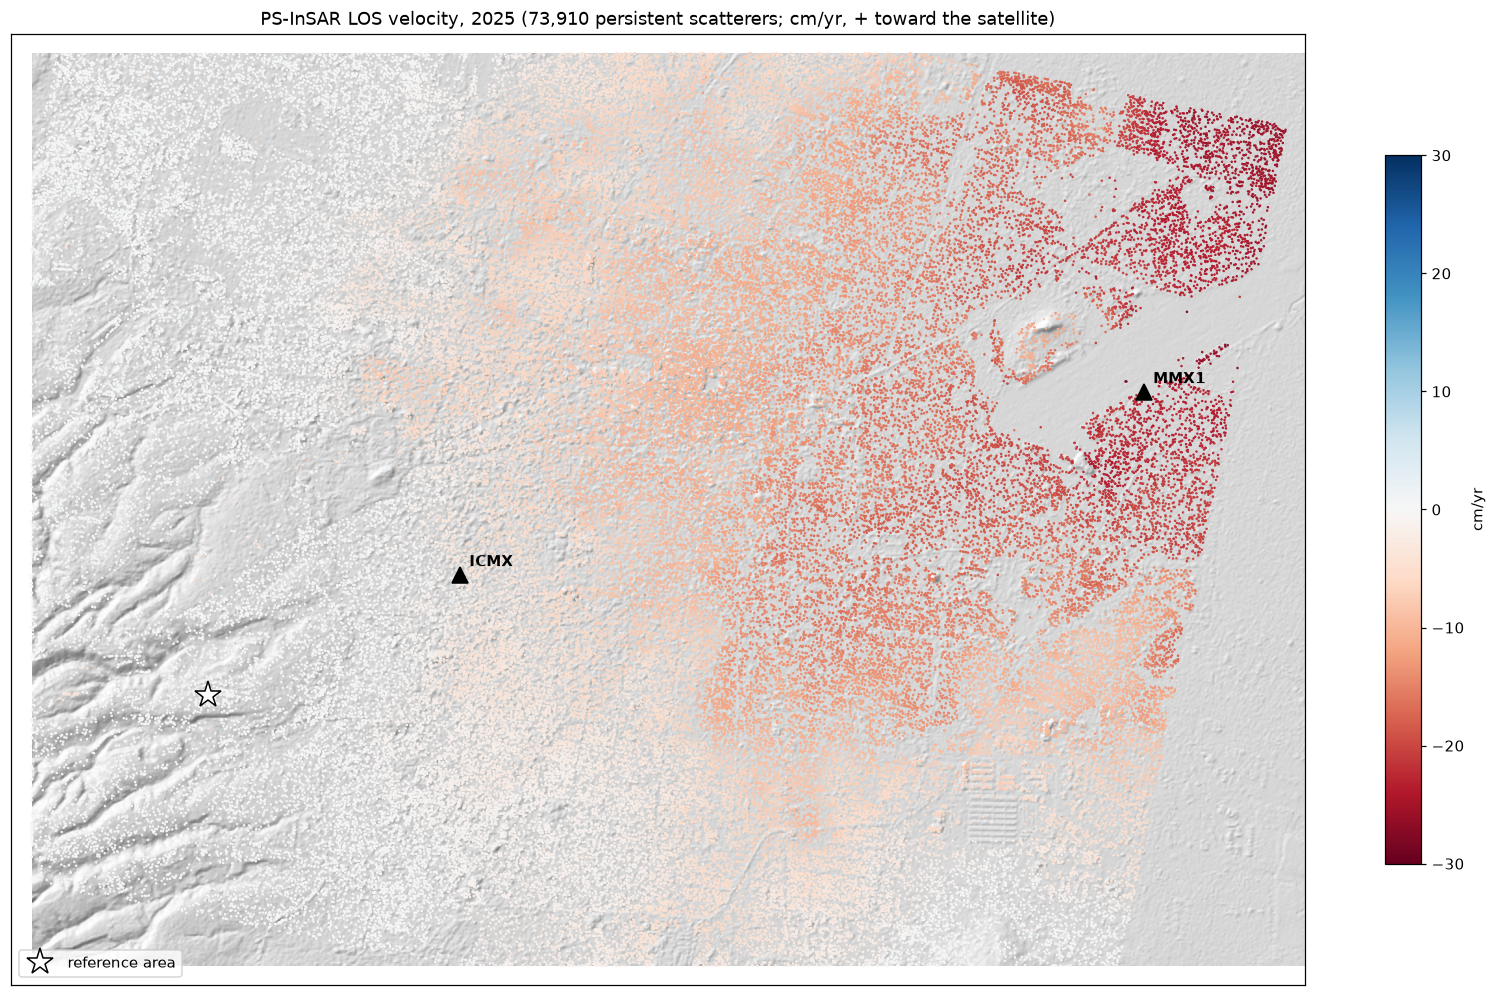

In [9]:
# Step 7. Geocode every PS onto a 10 m UTM grid, shift it by its DEM error, and map the velocities.

# 1. A 10 m grid a little larger than the PS window (0.01° of margin). resampling=2 is bilinear.
#    The ellipsoid DEM defines the grid. terrain_correct only needs the radar row and column of
#    each map cell, so the raster passed in is a dummy of zeros. near0 is the slant range of the
#    first sample of the debursted image.
to_utm = Transformer.from_crs(4326, UTM, always_xy=True)
# south-west corner of the PS window in UTM (with a margin)
x0, y0 = to_utm.transform(AOI_PS[0] - 0.01, AOI_PS[1] - 0.01)
x1, y1 = to_utm.transform(AOI_PS[2] + 0.01, AOI_PS[3] + 0.01)  # north-east corner
# 10 m UTM grid over the window
grid = dem_ell.rio.reproject(UTM, resolution=10, resampling=2).sel(x=slice(x0, x1), y=slice(y1, y0))
# slant range of the first column
near0 = a0["slant_range_time"] * sar.SPEED_OF_LIGHT / 2 + col0 * a0["range_pixel_spacing"]
# radar row and column of every grid cell
tc = sar.terrain_correct({"zero": np.zeros((2, 2), "float32")}, times, near0, a0["range_pixel_spacing"], orbit_ref, grid)
tc = xr.Dataset({"radar_row": tc["radar_row"], "radar_col": tc["radar_col"]})  # keep only those two layers

# 2. geocode_points inverts that grid for every PS. With height_error set, a scatterer Δh above
#    the DEM is moved toward the radar by Δh / tan θ, along the ground-range direction given by
#    the heading. The call without it is the position on the DEM surface, so the difference is
#    how far the height correction moved each point.
gx, gy = sar.geocode_points(prr, pcc, tc, height_error=dh[ps], incidence_deg=geom["incidence"][prr, pcc],
                            heading_deg=a0["heading"])
gx0, gy0 = sar.geocode_points(prr, pcc, tc)  # PS positions without the DEM-error correction
shift = np.hypot(gx - gx0, gy - gy0)  # how far the correction moved each PS

# 3. One row per PS: velocity, the RMSE of the linear fit (cm × 10 = mm), temporal coherence,
#    DEM error, amplitude dispersion, and the radar coordinates. Points that fell outside the
#    map grid, or have no velocity, are dropped, and the displacement series is cut to match.
pts = gpd.GeoDataFrame({"velocity_cm_yr": vel["velocity"], "rmse_mm": vel["rmse"] * 10, "coherence": gamma[ps],
                        "dem_error_m": dh[ps], "amp_dispersion": DA[prr, pcc], "radar_row": prr, "radar_col": pcc},
                       geometry=gpd.points_from_xy(gx, gy), crs=UTM)
ok_pts = np.isfinite(gx) & np.isfinite(pts.velocity_cm_yr.values)  # points with a valid position and velocity
pts = pts[ok_pts]  # keep them
los_ok = los[:, ok_pts]  # and their displacement series
# geolocation shift
print(f"{len(pts):,} PS geolocated; DEM-error correction moved points by a median {np.nanmedian(shift):.1f} m "
      f"(95th percentile {np.nanpercentile(shift, 95):.1f} m)")
# velocity statistics
print(f"LOS velocity: 1st percentile {np.percentile(pts.velocity_cm_yr, 1):.1f} cm/yr, median {pts.velocity_cm_yr.median():.1f} cm/yr")

# 4. Velocity over a hillshade of the geoid DEM. The colour scale is symmetric, so red is motion
#    toward the satellite and blue is motion away from it (subsidence, on this descending track).
#    Triangles are the GNSS stations; the star is the reference area.
ls = LightSource(azdeg=315, altdeg=40)
dem_utm = dem_geoid.rio.reproject_match(grid, resampling=2)  # geoid heights on the grid
ext = [float(grid.x.min()), float(grid.x.max()), float(grid.y.min()), float(grid.y.max())]  # map extent
st_xy = {s: to_utm.transform(*ll) for s, ll in STATIONS.items()}  # GNSS station positions in UTM
fig, ax = plt.subplots(figsize=(15, 9.5))  # one large panel
# hillshade background
ax.imshow(ls.hillshade(np.nan_to_num(dem_utm.values), vert_exag=2, dx=10, dy=10), cmap="gray", extent=ext, alpha=0.6)
# PS points coloured by velocity
sc = ax.scatter(pts.geometry.x, pts.geometry.y, c=pts.velocity_cm_yr, s=0.4, cmap="RdBu", vmin=-30, vmax=30, rasterized=True)
for s, (x, y) in st_xy.items():  # each station
    # a triangle and the name
    ax.plot(x, y, "k^", ms=10); ax.annotate(s, (x, y), xytext=(6, 6), textcoords="offset points", fontweight="bold")
sx, sy = to_utm.transform(*STABLE)  # the stable reference point in UTM
ax.plot(sx, sy, "w*", ms=18, mec="k", label="reference area")  # marked with a star
# title and limits
ax.set(title=f"PS-InSAR LOS velocity, 2025 ({len(pts):,} persistent scatterers; cm/yr, + toward the satellite)",
       xlim=(min(pts.geometry.x) - 300, max(pts.geometry.x) + 300), ylim=(min(pts.geometry.y) - 300, max(pts.geometry.y) + 300),
       xticks=[], yticks=[])
plt.colorbar(sc, ax=ax, shrink=0.7, label="cm/yr"); ax.legend(loc="lower left")  # colour bar and legend
plt.tight_layout(); plt.show()  # arrange and draw

73,910 PS are geolocated (the rest fall just outside the 10 m map grid around the PS window). The DEM-error correction moves them by a median of 7.3 m, and by up to 27 m for the 5 % with the largest height errors, which matters at this resolution.

The velocity map reproduces the city's subsidence bowl point by point. Points on the volcanic hills in the west, and the PS near the reference area, are stable. Velocities decrease steadily eastward over the lake-bed clays, to more than −25 cm/yr in the line of sight in the east, around MMX1 and to its north-east. The 1st percentile of all PS is −24.7 cm/yr and the median −5.5 cm/yr. The small rock hill north-west of MMX1 stands out as nearly stable inside fast-sinking ground. Open ground (the airport, parks and the dry lake bed) has no PS, as expected.

#### Validation against GNSS

As in the DInSAR notebook, the stations' daily positions (Nevada Geodetic Laboratory) are
projected onto the line of sight with `sar.los_unit_vector` and `insar.enu_to_los`, and compared
with the median of the PS within 150 m of each station. MMX1 has a data gap from October 2024 to
September 2025, so its rate comes from a linear fit across the gap.


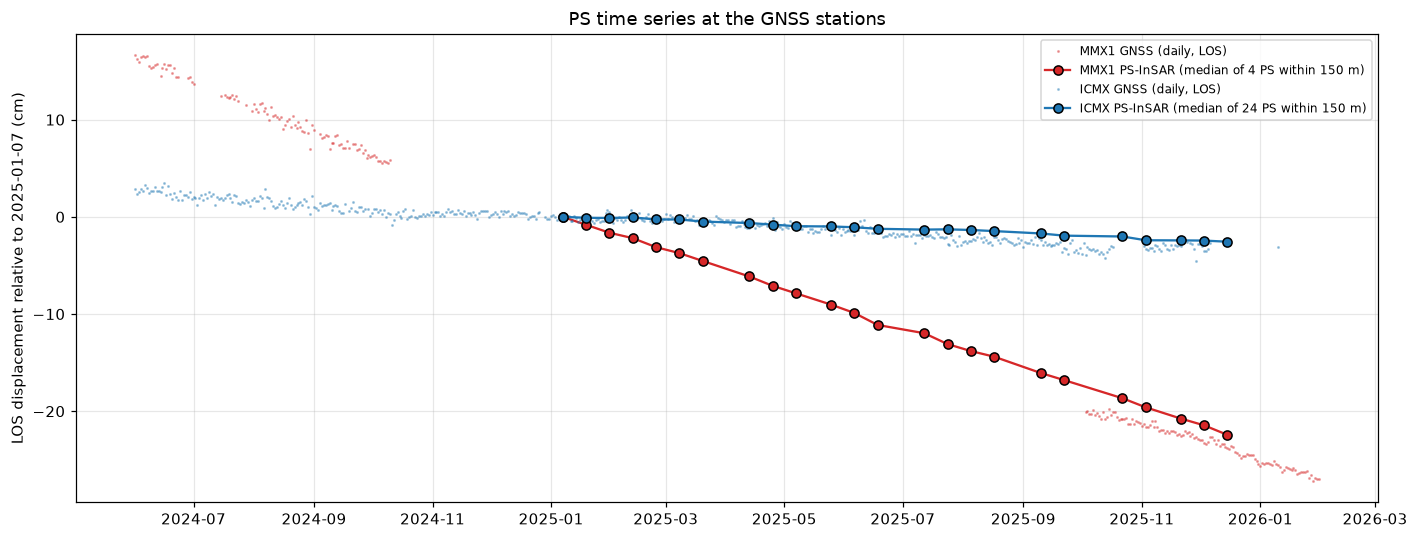

,PS within 150 m,GNSS LOS rate (cm/yr),PS LOS rate (cm/yr),"PS rate spread, IQR (cm/yr)"
MMX1,4.0,-25.74,-23.80,0.22
ICMX,24.0,-3.83,-2.81,0.51
MMX1 − ICMX,NaN,-21.91,-20.98,NaN


In [10]:
# Validation against GNSS. Project each station's daily east/north/up positions onto the
# line of sight and compare that series with the PS within 150 m of the station.

def read_ngl(station):
    # Nevada Geodetic Laboratory tenv3 file: daily IGS20 positions. The east, north and up
    # columns are a reference coordinate plus a small offset, both in metres.
    path = CACHE / f"{station}.tenv3"
    if not path.exists():  # download the station file once
        # Nevada Geodetic Laboratory daily positions
        urllib.request.urlretrieve(f"https://geodesy.unr.edu/gps_timeseries/IGS20/tenv3/IGS20/{station}.tenv3", path)
    df = pd.read_csv(path, sep=r"\s+")  # whitespace-separated table
    # east, north and up positions in metres
    return pd.DataFrame({"east": (df["_e0(m)"] + df["__east(m)"]).to_numpy(), "north": (df["____n0(m)"] + df["_north(m)"]).to_numpy(),
                         "up": (df["u0(m)"] + df["____up(m)"]).to_numpy()}, index=pd.to_datetime(df["YYMMMDD"], format="%y%b%d").to_numpy())


# 1. GNSS window around the 2025 dates, and the ground-to-satellite unit vector at each station
#    (east, north, up), from the precise orbit and the station height on the ellipsoid DEM.
GWIN = ("2024-06-01", "2026-01-31")               # GNSS window around the 2025 InSAR dates
gnss = {s: read_ngl(s).loc[GWIN[0]:GWIN[1]] for s in STATIONS}  # GNSS series inside the time window
# LOS unit vector at each station
los_vec = {s: sar.los_unit_vector(ll[1], ll[0], float(dem_ell.sel(x=ll[0], y=ll[1], method="nearest")), orbit_ref)
           for s, ll in STATIONS.items()}

# 2. For each station: the daily positions dotted with the LOS unit vector, a straight line
#    through that series (the rate MMX1 can offer across its 2025 gap), and the median of the
#    PS inside 150 m. The GNSS curve is drawn relative to the line's intercept and the PS
#    series relative to its first date, so the two slopes can be compared.
fig, ax = plt.subplots(figsize=(13, 5))
rows = {}  # comparison rows
for s, c in zip(STATIONS, ["tab:red", "tab:blue"]):  # each station with its colour
    g = gnss[s]  # its GNSS series
    # projected onto the LOS
    g_los = pd.Series(insar.enu_to_los(g.east, g.north, g.up, los_vec[s]), index=g.index)
    ty = (g_los.index - pd.Timestamp(dates_sorted[0])).days / 365.25  # time in years
    rate, icpt = np.polyfit(ty, g_los.values, 1)  # straight-line fit
    # PS within 150 m of the station
    near = np.hypot(pts.geometry.x - st_xy[s][0], pts.geometry.y - st_xy[s][1]) < 150
    ps_series = np.nanmedian(los_ok[:, near.values], axis=1)  # median PS displacement series
    # daily GNSS
    ax.plot(g_los.index, 100 * (g_los - icpt), ".", ms=2, alpha=0.35, color=c, label=f"{s} GNSS (daily, LOS)")
    ax.plot(pd.to_datetime(dates_sorted), 100 * (ps_series - ps_series[0]), "o-", color=c, mec="k",  # PS points
            label=f"{s} PS-InSAR (median of {near.sum()} PS within 150 m)")
    rows[s] = {"PS within 150 m": int(near.sum()), "GNSS LOS rate (cm/yr)": 100 * rate,  # GNSS and PS rates
               "PS LOS rate (cm/yr)": float(np.nanmedian(pts.velocity_cm_yr[near])),
               "PS rate spread, IQR (cm/yr)": float(np.subtract(*np.nanpercentile(pts.velocity_cm_yr[near], [75, 25])))}
# labels and title
ax.set(ylabel=f"LOS displacement relative to {dates_sorted[0]} (cm)", title="PS time series at the GNSS stations")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()  # legend, grid, arrange and draw

# 3. The station difference. Any constant added by the choice of reference area cancels
#    in both the GNSS column and the PS column.
val = pd.DataFrame(rows).T
# relative rate between the stations
val.loc["MMX1 − ICMX", ["GNSS LOS rate (cm/yr)", "PS LOS rate (cm/yr)"]] = (
    val.loc["MMX1", ["GNSS LOS rate (cm/yr)", "PS LOS rate (cm/yr)"]] - val.loc["ICMX", ["GNSS LOS rate (cm/yr)", "PS LOS rate (cm/yr)"]])
val.round(2)  # show the table

| | GNSS LOS rate | PS LOS rate | PS used |
|---|---|---|---|
| MMX1 | −25.7 cm/yr | −23.8 cm/yr | 4 within 150 m (IQR 0.2 cm/yr) |
| ICMX | −3.8 cm/yr | −2.8 cm/yr | 24 within 150 m (IQR 0.5 cm/yr) |
| MMX1 − ICMX | −21.9 cm/yr | −21.0 cm/yr | |

The PS rates agree with GNSS to within 1 to 2 cm/yr at the stations, and to 0.9 cm/yr for the difference between them. That matches the SBAS result of the DInSAR notebook (−24.6 and −3.1 cm/yr). The time series follows the GNSS trend through 2025, including across MMX1's long data gap. The PS near each station agree closely with one another (interquartile ranges of 0.2 to 0.5 cm/yr).

#### Comparison with the SBAS velocities of the DInSAR notebook

PS-InSAR and SBAS process the same kind of data in different ways (full-resolution points on a
star graph versus multilooked areas on a small-baseline network). Where both measure the ground,
their velocities should agree; where they differ, the PS may be on a structure that moves on its
own.


PS with an SBAS value: 68,515; correlation 0.994; PS − SBAS median +0.25 cm/yr, NMAD 0.46 cm/yr


,correlation with SBAS,PS − SBAS NMAD (cm/yr),PS differing by > 5 cm/yr
sequential unwrapping (used),0.994046,0.463457,0.33%
per-date (star) unwrapping,0.991381,0.462535,0.44%


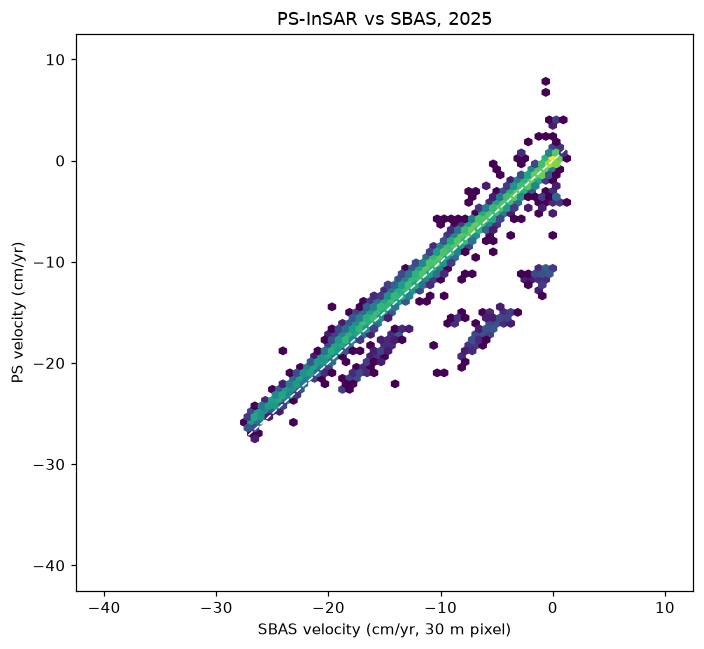

In [11]:
# Comparison with the SBAS velocity map written by the DInSAR notebook. The two chains share
# the acquisitions but not the processing: full-resolution points on a star graph here, 30 m
# pixels on a small-baseline network there.

sbas_file = Path("outputs/dinsar_mexico_city/mexico_city_2025_los_velocity_cm_per_yr.tif")
if sbas_file.exists():  # compare with the SBAS result if it exists
    # 1. The SBAS velocity in the map cell nearest each PS, and PS − SBAS where both exist.
    sbas = rioxarray.open_rasterio(sbas_file).squeeze(drop=True)
    # SBAS velocity at each PS
    sb = sbas.sel(x=xr.DataArray(pts.geometry.x.values, dims="p"), y=xr.DataArray(pts.geometry.y.values, dims="p"), method="nearest").values
    both = np.isfinite(sb) & np.isfinite(pts.velocity_cm_yr.values)  # points valid in both
    diff = pts.velocity_cm_yr.values[both] - sb[both]  # differences
    # correlation and differences
    print(f"PS with an SBAS value: {both.sum():,}; correlation {np.corrcoef(pts.velocity_cm_yr.values[both], sb[both])[0, 1]:.3f}; "
          f"PS − SBAS median {np.median(diff):+.2f} cm/yr, NMAD {1.4826 * np.median(np.abs(diff - np.median(diff))):.2f} cm/yr")

    # 2. The same points from the per-date (star) unwrapping instead of the sequential one:
    #    subtract that series' own APS, convert phase to cm/yr, and keep the geolocated points.
    star_clean = star_phase - insar.atmospheric_filter(star_phase, pxx, pyy, t_years, spatial_sigma=1000, cell=100)
    # velocity from the star unwrapping
    v_star = insar.point_velocity(insar.phase_to_los(star_clean, lam) * 100, t_years)["velocity"][ok_pts]

    # 3. Correlation, the robust spread of PS − SBAS (NMAD: the median absolute deviation
    #    scaled so it matches a standard deviation), and the share that disagree by more than 5 cm/yr.
    rows = {}
    # compare both unwrapping strategies with SBAS
    for name, v in [("sequential unwrapping (used)", pts.velocity_cm_yr.values), ("per-date (star) unwrapping", v_star)]:
        ok_ = both & np.isfinite(v)  # valid points
        d_ = v[ok_] - sb[ok_]  # differences
        rows[name] = {"correlation with SBAS": np.corrcoef(v[ok_], sb[ok_])[0, 1],  # statistics
                      "PS − SBAS NMAD (cm/yr)": 1.4826 * np.median(np.abs(d_ - np.median(d_))),
                      "PS differing by > 5 cm/yr": f"{np.mean(np.abs(d_) > 5):.2%}"}
    display(pd.DataFrame(rows).T.round(3))  # show the table

    # 4. A hexagon bin coloured by count, rather than one mark per PS. The dashed line is 1:1.
    fig, ax = plt.subplots(figsize=(6.5, 6))
    # density plot of PS against SBAS velocity
    ax.hexbin(sb[both], pts.velocity_cm_yr.values[both], gridsize=80, bins="log", extent=(-40, 10, -40, 10), cmap="viridis")
    ax.plot([-40, 10], [-40, 10], "w--", lw=1)  # the 1:1 line
    # labels and title
    ax.set(xlabel="SBAS velocity (cm/yr, 30 m pixel)", ylabel="PS velocity (cm/yr)", title="PS-InSAR vs SBAS, 2025")
    plt.tight_layout(); plt.show()  # arrange and draw
else:
    # SBAS output not found
    print("Run Notebook 07_03_01_04 (DInSAR) first to compare with its SBAS velocities.")

68,515 PS fall on valid SBAS pixels. Their velocities correlate with SBAS at **0.994**; PS are 0.25 cm/yr less negative in the median, and the robust spread (NMAD) of the difference is 0.46 cm/yr. Two very different processing chains (full-resolution points on a 23-interferogram star graph, versus 30 m pixels on a 21-pair small-baseline network) agree within half a centimetre per year.

Only 0.33 % of PS differ from SBAS by more than 5 cm/yr, against 0.44 % with per-date unwrapping. Before sequential unwrapping was used, the disagreeing PS clustered on the rock hill next to MMX1; where stable and sinking ground meet, a 30 m SBAS pixel mixes both while a PS does not, so some disagreement there is expected.


In [12]:
# Write the PS. The GeoPackage is one point per scatterer, in UTM, with velocity and the
# quality columns. The NetCDF is the LOS displacement time series (metres, positive toward
# the satellite), in the same point order, with each point's map coordinates.
pts.to_file(OUT / "mexico_city_2025_ps.gpkg", driver="GPKG")
ts = xr.DataArray(los_ok.astype("float32"), dims=("time", "point"),  # displacement time series of every PS
                  coords={"time": pd.to_datetime(dates_sorted), "x": ("point", pts.geometry.x.values), "y": ("point", pts.geometry.y.values)},
                  name="los_displacement", attrs={"units": "m", "positive": "toward the satellite", "crs": UTM})
ts.to_netcdf(OUT / "mexico_city_2025_ps_timeseries.nc")  # save it
print("saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")  # list the saved files

saved:
  mexico_city_2025_ps.gpkg
  mexico_city_2025_ps_timeseries.nc


## Summary, exercises and references

- **Steps 1 to 2.** 24 Sentinel-1 IW SLC dates of 2025 (descending track 41, 12 Sentinel-1A and 12 Sentinel-1C) were co-registered to 25 May 2025 with back-geocoding and ESD (`sar.coregister_stack`), and 23 single-reference differential interferograms were formed at full resolution.
- **Step 3.** Amplitude dispersion (24 calibrated amplitudes, D_A < 0.25, one candidate per amplitude peak) gave 95,710 candidates in a 354 km² window.
- **Step 4.** StaMPS-style phase-stability estimation (spatially correlated phase removed, DEM error from the periodogram, three iterations) kept 83,789 PS with temporal coherence above the 1 %-false-positive threshold of 0.49: 237 PS per km².
- **Step 5.** Sparse unwrapping through a SNAPHU grid, applied to consecutive-date differences, recovered a stable rock outcrop that per-date unwrapping gave its neighbours' cycles.
- **Step 6.** The DEM error moved PS by a median of 7 m. The atmospheric filter (high-pass in time, low-pass in space) reduced the scatter about each PS's trend from 4.3 to 1.3 mm.
- **Step 7.** LOS velocities of −23.8 cm/yr at MMX1 and −2.8 cm/yr at ICMX agree with GNSS (−25.7 and −3.8) within 1 to 2 cm/yr, and the PS velocities match the SBAS map of the DInSAR notebook with a correlation of 0.994 and a robust difference of 0.46 cm/yr. The PS are saved as a GeoPackage, and their time series as NetCDF, in `outputs/psinsar_mexico_city/`.

**Limitations.** One year of data, a linear temporal model in the APS filter, one look direction (LOS only), and a simplified unwrapping compared with full 3-D methods. The PS are point measurements: on a building they measure the building, which is the point of PS-InSAR, but also why a PS can differ from the ground around it.

### Exercises

1. Lower the candidate threshold to D_A < 0.4 (StaMPS). How many more PS pass the temporal
   coherence test, and where are they?
2. Replace the 1 % false-positive rate with 5 % and 0.1 %. How do PS density and the velocity
   scatter near the GNSS stations change?
3. Look at the PS with the largest positive DEM errors. Are they on tall buildings? (Copernicus DEM
   is a surface model from 2011 to 2015, so newer buildings show up as DEM error.)
4. Estimate velocity together with DEM error in Step 4 (`ps_periodogram(..., time_years=..., velocity_phase=...)`)
   instead of removing the spatially correlated phase. Which approach gives more PS in the fastest-sinking area?
5. Drop half the dates (keep every second one) and repeat. How does D_A behave with 12 images?
